In [1]:
!pip install -q --no-cache-dir --force-reinstall --no-deps git+https://github.com/RayenSansa03/aeroguard.git@main

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
from google.colab import drive
drive.mount("/content/drive")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost
from sklearn.metrics import average_precision_score

from aeroguard.augmentation import smote_simple
from aeroguard.autoencodeurs import standardiser, statistiques_features
from aeroguard.comparaison import bootstrap_moteurs, comparer_a_reference
from aeroguard.donnees_ml import preparer_xy
from aeroguard.metier import alertes_confirmees, evaluer_alerte
from aeroguard.modeles import creer_xgboost
from aeroguard.registre import doit_promouvoir

DOSSIER = "/content/drive/MyDrive/aeroguard"
FAMILLE_RARE = "fan"
SEUIL_XGB, K_XGB = 0.81, 3          # réglages figés de la v3
GAIN_FAN_MINIMAL = 0.01             # taille d'effet minimale (leçon 6.5)

vols = pd.read_parquet(f"{DOSSIER}/data/processed/vols_ncmapss.parquet")
morceaux = [preparer_xy(vols, g) for g in ("train", "val")]
X_pool = pd.concat([X for X, _ in morceaux])
y_pool = pd.concat([y for _, y in morceaux]).to_numpy()
familles_pool = vols.loc[X_pool.index, "famille"].astype(str).to_numpy()

X_test, y_test = preparer_xy(vols, "test")
y_test = np.asarray(y_test)
infos_test = vols.loc[X_test.index, ["moteur", "cycle", "RUL", "famille"]].copy()
infos_test["famille"] = infos_test["famille"].astype(str)
fan_test = (infos_test["famille"] == FAMILLE_RARE).to_numpy()

print(f"Entraînement : {len(X_pool)} vols ({len(np.unique(vols.loc[X_pool.index, 'moteur']))} moteurs)")
print(f"Test : {len(X_test)} vols, {infos_test['moteur'].nunique()} moteurs, "
      f"dont {infos_test.loc[fan_test, 'moteur'].nunique()} moteurs fan")

Mounted at /content/drive
Entraînement : 4535 vols (60 moteurs)
Test : 2938 vols, 39 moteurs, dont 4 moteurs fan


In [4]:
rare = (familles_pool == FAMILLE_RARE) & (y_pool == 1)
X_rare = X_pool[rare].fillna(X_pool.median())
moy, ec = statistiques_features(X_rare.to_numpy(dtype="float64"))
ec = np.where(np.asarray(ec) > 0, ec, 1.0)
X_rare_std = standardiser(X_rare.to_numpy(dtype="float64"), moy, ec)
faux = pd.DataFrame(smote_simple(X_rare_std, len(X_rare), graine=42) * ec + moy, columns=X_pool.columns)

jeux = {
    "sans_ajout": (X_pool, y_pool),
    "smote": (pd.concat([X_pool, faux], ignore_index=True), np.r_[y_pool, np.ones(len(faux))]),
}
probas = {}
for nom, (X_app, y_app) in jeux.items():
    modele = creer_xgboost("cpu", early_stopping_rounds=None, n_estimators=411)
    modele.fit(X_app, y_app)
    probas[nom] = modele.predict_proba(X_test)[:, 1]
print(f"{len(X_rare)} vols usés fan réels + {len(faux)} vols SMOTE ajoutés au modèle « smote »")

407 vols usés fan réels + 407 vols SMOTE ajoutés au modèle « smote »


In [5]:
lignes = []
for nom, p in probas.items():
    tout = evaluer_alerte(y_test, p, SEUIL_XGB, infos_test, k=K_XGB)
    fan = evaluer_alerte(y_test[fan_test], p[fan_test], SEUIL_XGB, infos_test[fan_test], k=K_XGB)
    lignes.append({
        "modele": nom,
        "f1_macro": tout["f1_macro"],
        "pr_auc": average_precision_score(y_test, p),
        "moteurs_detectes": f"{tout['moteurs_detectes']}/{tout['moteurs']}",
        "avance_moyenne": tout["avance_moyenne"],
        "fausses_alarmes": tout["fausses_alarmes_total"],
        "pr_auc_fan": average_precision_score(y_test[fan_test], p[fan_test]),
        "fan_detectes": f"{fan['moteurs_detectes']}/{fan['moteurs']}",
        "avance_fan": fan["avance_moyenne"],
    })
test_v6 = pd.DataFrame(lignes).set_index("modele")
test_v6.to_csv(f"{DOSSIER}/results/v6_test_final.csv")
test_v6.round(3)

,f1_macro,pr_auc,moteurs_detectes,avance_moyenne,fausses_alarmes,pr_auc_fan,fan_detectes,avance_fan
modele,,,,,,,,
sans_ajout,0.851,0.977,39/39,40.000,37,0.975,4/4,48.0
smote,0.854,0.977,39/39,40.179,32,0.975,4/4,49.5


In [6]:
def confirmer(p):
    """Alertes confirmées sur K_XGB vols d'affilée, moteur par moteur."""
    table = infos_test.assign(alerte=(p >= SEUIL_XGB).astype(int)).sort_values(["moteur", "cycle"])
    table["confirmee"] = table.groupby("moteur")["alerte"].transform(
        lambda s: alertes_confirmees(s.to_numpy(), K_XGB))
    return table["confirmee"].reindex(infos_test.index).to_numpy()


alertes = {nom: confirmer(p) for nom, p in probas.items()}
tirages = bootstrap_moteurs(infos_test["moteur"].to_numpy(), y_test, alertes, n_tirages=1000, graine=42)
comparaison = comparer_a_reference(tirages, "sans_ajout")
print(comparaison.round(4))

gain_fan = test_v6.loc["smote", "pr_auc_fan"] - test_v6.loc["sans_ajout", "pr_auc_fan"]
promotion = doit_promouvoir(comparaison, "smote")
adopter = bool(promotion and gain_fan >= GAIN_FAN_MINIMAL)
print(f"\nRègle du registre (D4) : promouvoir SMOTE ? {promotion}")
print(f"Gain PR-AUC fan : {gain_fan:+.4f} (minimum exigé : +{GAIN_FAN_MINIMAL})")
print(f"➡️ DÉCISION : {'adopter XGBoost + SMOTE' if adopter else 'garder le champion actuel (XGBoost sans ajout)'}")

with open(f"{DOSSIER}/results/v6_decision.json", "w") as f:
    json.dump({"adopter_smote": adopter, "promotion_registre": promotion, "gain_pr_auc_fan": round(float(gain_fan), 4),
               "ecart_f1": round(float(comparaison.loc["smote", "ecart_moyen"]), 4),
               "ic95_ecart_f1": [round(float(comparaison.loc["smote", "ecart_bas"]), 4),
                                 round(float(comparaison.loc["smote", "ecart_haut"]), 4)]}, f, indent=2)

            f1_macro_moyen  ecart_moyen  ecart_bas  ecart_haut  \
modele                                                           
sans_ajout          0.8299       0.0000     0.0000      0.0000   
smote               0.8360       0.0061    -0.0019      0.0149   

            proba_meilleur  difference_prouvee  
modele                                          
sans_ajout           0.000               False  
smote                0.925               False  

Règle du registre (D4) : promouvoir SMOTE ? False
Gain PR-AUC fan : +0.0005 (minimum exigé : +0.01)
➡️ DÉCISION : garder le champion actuel (XGBoost sans ajout)


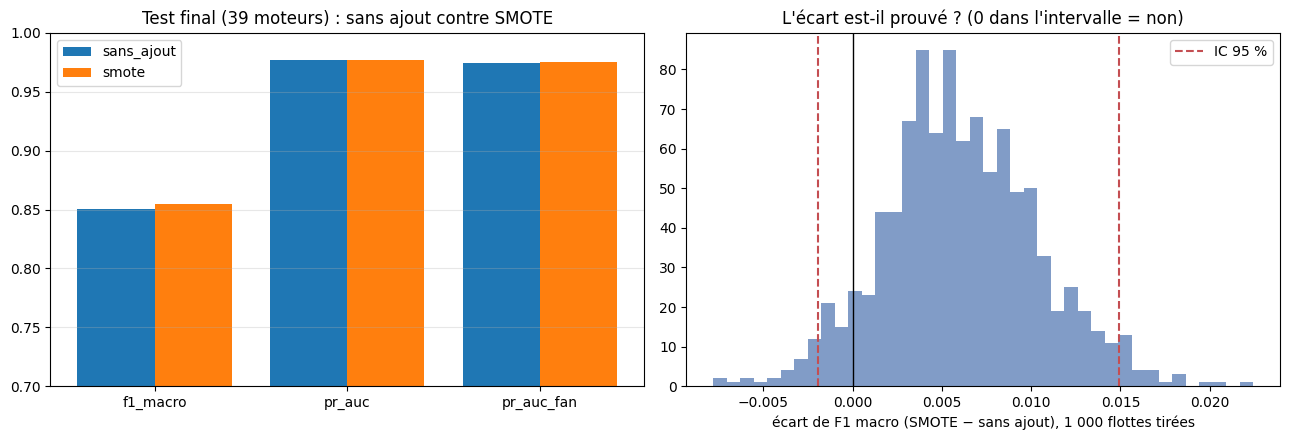

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

mesures = ["f1_macro", "pr_auc", "pr_auc_fan"]
positions = np.arange(len(mesures))
for decalage, nom in [(-0.2, "sans_ajout"), (0.2, "smote")]:
    ax1.bar(positions + decalage, test_v6.loc[nom, mesures].astype(float), 0.4, label=nom)
ax1.set_xticks(positions, mesures)
ax1.set_ylim(0.7, 1.0)
ax1.set_title("Test final (39 moteurs) : sans ajout contre SMOTE")
ax1.legend()
ax1.grid(alpha=0.3, axis="y")

ecarts = tirages["smote"] - tirages["sans_ajout"]
ax2.hist(ecarts, bins=40, color="#4C72B0", alpha=0.7)
ax2.axvline(0, color="black", linewidth=1)
ax2.axvline(comparaison.loc["smote", "ecart_bas"], color="#C44E52", linestyle="--", label="IC 95 %")
ax2.axvline(comparaison.loc["smote", "ecart_haut"], color="#C44E52", linestyle="--")
ax2.set_xlabel("écart de F1 macro (SMOTE − sans ajout), 1 000 flottes tirées")
ax2.set_title("L'écart est-il prouvé ? (0 dans l'intervalle = non)")
ax2.legend()

plt.tight_layout()
plt.savefig(f"{DOSSIER}/results/figures/66_test_final_v6.png", dpi=150, bbox_inches="tight")
plt.show()